#mounting from drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#setting file path

In [2]:
file_path_1 = '/content/drive/My Drive/SL assignment 2'


#converting csv file in drive into df

In [3]:
import pandas as pd

file_path_2 = '/content/drive/My Drive/SL assignment 2/MHpredict.csv'
df_MHpredict = pd.read_csv(file_path_2)


#inspecting DF

In [4]:
print(df_MHpredict)

                  disType    Sexe  Age  aedu  IDS  BAI  FQ    LCImax pedigree  \
0        anxiety disorder    male   53     9    4    6   0  0.400000      Yes   
1        anxiety disorder  female   25    15   12   14  14  0.518519      Yes   
2       comorbid disorder  female   41     9   15   13   0  0.610169      Yes   
3     depressive disorder    male   56     6    9   12   6  0.672727      Yes   
4       comorbid disorder  female   64    10   15   22  16  1.000000      Yes   
...                   ...     ...  ...   ...  ...  ...  ..       ...      ...   
1495     anxiety disorder  female   59     5    8    6   8  0.480000      Yes   
1496    comorbid disorder  female   35    12    6    7   5  0.100000      Yes   
1497     anxiety disorder    male   23    12   11   11   7  0.381818       No   
1498     anxiety disorder  female   48     9   12   17   0  0.346939       No   
1499    comorbid disorder  female   40    12   17   19   8  0.872727      Yes   

                           

#inspecting columns of DF

In [5]:
print(df_MHpredict.columns)


Index(['disType', 'Sexe', 'Age', 'aedu', 'IDS', 'BAI', 'FQ', 'LCImax',
       'pedigree', 'alcohol', 'bTypeDep', 'bSocPhob', 'bGAD', 'bPanic', 'bAgo',
       'AO', 'RemDis', 'sample', 'ADuse', 'PsychTreat', 'dep_sev_fu'],
      dtype='object')


#import statements

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error


#student number defined

In [7]:
student_number = 4402375

#Y variable set to the dep_sev_fu column

In [8]:
Y = df_MHpredict['dep_sev_fu']


# X variable set to everything in DF besides dep_sev_fu column

In [9]:
X = df_MHpredict.drop(columns=['dep_sev_fu'])

#printing the Sexe column in DF

In [10]:
print(df_MHpredict['Sexe'])


0         male
1       female
2       female
3         male
4       female
         ...  
1495    female
1496    female
1497      male
1498    female
1499    female
Name: Sexe, Length: 1500, dtype: object


#categorical columns divided into 2
### conversion : Sexe --> Sexe_male and Sexe_female

In [11]:
X = pd.get_dummies(X)


In [12]:
print(X)

      Age  aedu  IDS  BAI  FQ    LCImax  AO  RemDis  ADuse  PsychTreat  ...  \
0      53     9    4    6   0  0.400000  21    True  False        True  ...   
1      25    15   12   14  14  0.518519  14   False   True        True  ...   
2      41     9   15   13   0  0.610169  15   False   True        True  ...   
3      56     6    9   12   6  0.672727  21   False  False        True  ...   
4      64    10   15   22  16  1.000000  54   False   True       False  ...   
...   ...   ...  ...  ...  ..       ...  ..     ...    ...         ...  ...   
1495   59     5    8    6   8  0.480000  40    True  False       False  ...   
1496   35    12    6    7   5  0.100000  18   False  False       False  ...   
1497   23    12   11   11   7  0.381818  12   False  False       False  ...   
1498   48     9   12   17   0  0.346939   6   False   True        True  ...   
1499   40    12   17   19   8  0.872727  20   False  False       False  ...   

      bSocPhob_Positive  bGAD_Negative  bGAD_Positi

#splitting dataset

In [13]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, train_size=1000, test_size=500, random_state=student_number
)

#inspecting dimensions of train and test portions

In [14]:
print("Dimensions of X_train:", X_train.shape)
print("Dimensions of X_test:", X_test.shape)
print("Dimensions of y_train:", Y_train.shape)
print("Dimensions of y_test:", Y_test.shape)

Dimensions of X_train: (1000, 34)
Dimensions of X_test: (500, 34)
Dimensions of y_train: (1000,)
Dimensions of y_test: (500,)


#checking numeric and categorical columns

In [15]:
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categoric_features = X_train.select_dtypes(include=['object', 'bool']).columns.tolist()


In [16]:
print("Numerical Features:", numeric_features)
print("Categorical Features:", categoric_features)

Numerical Features: ['Age', 'aedu', 'IDS', 'BAI', 'FQ', 'LCImax', 'AO']
Categorical Features: ['RemDis', 'ADuse', 'PsychTreat', 'disType_anxiety disorder', 'disType_comorbid disorder', 'disType_depressive disorder', 'Sexe_female', 'Sexe_male', 'pedigree_No', 'pedigree_Yes', 'alcohol_Diagnose alcohol dependent or alcohol abuse', 'alcohol_No positive alcohol diagnose', 'bTypeDep_Dysthymia', 'bTypeDep_First onset MDD', 'bTypeDep_No depressive disorder', 'bTypeDep_Recurrent MDD', 'bSocPhob_Negative', 'bSocPhob_Positive', 'bGAD_Negative', 'bGAD_Positive', 'bPanic_Negative', 'bPanic_Positive', 'bAgo_Negative', 'bAgo_Positive', 'sample_General population', 'sample_Primary care', 'sample_Specialised mental health care']


In [17]:
print(X_train)

      Age  aedu  IDS  BAI  FQ    LCImax  AO  RemDis  ADuse  PsychTreat  ...  \
210    46    18   16   14  15  0.118644  24   False   True        True  ...   
86     26    11   12   10   2  0.240000  24   False  False        True  ...   
71     30    15   16    9   0  0.372549  19   False  False        True  ...   
42     37    10   12   17  16  0.714286  18    True  False        True  ...   
11     24    11   18   11  11  0.150943  46   False  False        True  ...   
...   ...   ...  ...  ...  ..       ...  ..     ...    ...         ...  ...   
1181   39    15    5    2   8  0.183333  23   False  False        True  ...   
252    37    15    9   16  12  0.301887  16   False   True        True  ...   
368    34     9   18   20   0  1.000000   4   False  False       False  ...   
564    58    11   14   11   3  0.132075  37   False   True        True  ...   
1335   44    12   17   27  11  0.600000  10   False   True        True  ...   

      bSocPhob_Positive  bGAD_Negative  bGAD_Positi

#preprocessor transformers defined

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categoric_features)
    ]
)

#quick check of preprocessing steps

In [19]:
from sklearn.feature_extraction import FeatureHasher
import pandas as pd

X_train_preprocessed = preprocessor.fit_transform(X_train)
print("Transformed shape:", X_train_preprocessed.shape)

one_hot_encoded_features = preprocessor.named_transformers_['cat']
standard_scaled_features = preprocessor.named_transformers_['num']

ohe_feature_names = one_hot_encoded_features.get_feature_names_out(categoric_features)
standard_scaled_features_names = standard_scaled_features.get_feature_names_out(numeric_features)

all_feature_ohe_ss = list(standard_scaled_features_names) + list(ohe_feature_names)

X_train_df = pd.DataFrame(X_train_preprocessed.toarray() if hasattr(X_train_preprocessed, "toarray") else X_train_preprocessed,
                          columns=all_feature_ohe_ss)




Transformed shape: (1000, 61)


In [20]:
print(X_train_df.head())


        Age      aedu       IDS       BAI        FQ    LCImax        AO  \
0  0.363795  1.944338  0.874219  0.508295  0.906157 -1.117266  0.254337   
1 -1.223442 -0.210565  0.060235 -0.066862 -0.822643 -0.760921  0.254337   
2 -0.905995  1.020808  0.874219 -0.210651 -1.088612 -0.371708 -0.151175   
3 -0.350462 -0.518408  0.060235  0.939663  1.039142  0.631755 -0.232277   
4 -1.382166 -0.210565  1.281211  0.076927  0.374219 -1.022423  2.038588   

   RemDis_False  RemDis_True  ADuse_False  ...  bAgo_Negative_False  \
0           1.0          0.0          0.0  ...                  0.0   
1           1.0          0.0          1.0  ...                  0.0   
2           1.0          0.0          1.0  ...                  0.0   
3           0.0          1.0          1.0  ...                  0.0   
4           1.0          0.0          1.0  ...                  0.0   

   bAgo_Negative_True  bAgo_Positive_False  bAgo_Positive_True  \
0                 1.0                  1.0              

#SVM pipeline creation

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

svm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('svm', SVC())
])

#hyperparameter tuning grid defined

In [22]:
param_grid = {
    'svm__C': [0.01, 0.1, 1, 10, 15, 20, 25, 30],
    'svm__gamma': [0.0001, 0.001, 0.01, 0.1, 1, 10],
    'svm__kernel': ['rbf', 'poly', 'sigmoid']
}


In [23]:
print(Y_train.value_counts())


dep_sev_fu
 15    89
 13    79
 12    64
 14    63
 10    62
 11    61
 16    61
 17    59
 9     55
 18    55
 19    48
 7     39
 8     37
 20    35
 21    32
 22    30
 6     23
 5     22
 4     15
 23    15
 25    11
 3     10
 24     8
 2      7
 27     6
 26     6
 1      4
 0      1
-1      1
-2      1
-4      1
Name: count, dtype: int64


#Stratified K Fold with number of splits = 10 and original data used

In [46]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=student_number)

grid_search = GridSearchCV(svm_pipeline, param_grid, cv=cv, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, Y_train)

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
print("Best parameters:", grid_search.best_params_)
print("\nClassification report:\n", classification_report(Y_test, y_pred))

/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=10.
  warnings.warn(


Best parameters: {'svm__C': 1, 'svm__gamma': 0.01, 'svm__kernel': 'sigmoid'}

Classification report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.00      0.00      0.00         2
           2       0.00      0.00      0.00         1
           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00         5
           5       0.00      0.00      0.00        10
           6       0.00      0.00      0.00        15
           7       0.00      0.00      0.00        16
           8       0.00      0.00      0.00        13
           9       0.00      0.00      0.00        29
          10       0.00      0.00      0.00        35
          11       0.00      0.00      0.00        35
          12       0.00      0.00      0.00        45
          13       0.00      0.00      0.00        39
          14       0.00      0.00      0.00        40
          15       0.08      1.00

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#changing param grid

In [47]:
param_grid2 = {
    'svm__C': [0.001, 0.1, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 10, 15, 20, 25, 30],
    'svm__gamma': [0.0001, 0.001, 0.01, 0.1,0.15,0.20,0.30, 1, 10],
    'svm__kernel': ['rbf']
}


In [48]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report

cv2 = StratifiedKFold(n_splits=10, shuffle=True, random_state=student_number)

grid_search2 = GridSearchCV(svm_pipeline, param_grid2, cv=cv2, scoring='accuracy', n_jobs=-1)
grid_search2.fit(X_train, Y_train)

best_model2 = grid_search2.best_estimator_
y_pred2 = best_model2.predict(X_test)
print("Best parameters:", grid_search2.best_params_)
print("\nClassification report:\n", classification_report(Y_test, y_pred2))

/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=10.
  warnings.warn(


Best parameters: {'svm__C': 0.9, 'svm__gamma': 0.2, 'svm__kernel': 'rbf'}

Classification report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.00      0.00      0.00         2
           2       0.00      0.00      0.00         1
           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00         5
           5       0.00      0.00      0.00        10
           6       0.00      0.00      0.00        15
           7       0.00      0.00      0.00        16
           8       0.00      0.00      0.00        13
           9       0.50      0.03      0.06        29
          10       0.00      0.00      0.00        35
          11       0.00      0.00      0.00        35
          12       0.22      0.04      0.07        45
          13       0.17      0.08      0.11        39
          14       0.00      0.00      0.00        40
          15       0.07      0.87   

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#Stratified K Fold with number of splits = 10 and filtered data used

In [50]:
train_data = pd.concat([X_train, Y_train], axis=1)
label_counts = Y_train.value_counts()
valid_labels = label_counts[label_counts > 5].index
filtered_train_data = train_data[train_data[Y_train.name].isin(valid_labels)]

X_train_filtered = filtered_train_data.drop(columns=[Y_train.name])
Y_train_filtered = filtered_train_data[Y_train.name]

common_classes = set(Y_train_filtered.unique()) & set(Y_test.unique())
X_test_filtered = X_test[Y_test.isin(common_classes)]
Y_test_filtered = Y_test[Y_test.isin(common_classes)]

cv3 = StratifiedKFold(n_splits=10, shuffle=True, random_state=student_number)
grid_search3 = GridSearchCV(svm_pipeline, param_grid2, cv=cv3, scoring='accuracy', n_jobs=-1)
grid_search3.fit(X_train_filtered, Y_train_filtered)

best_model3 = grid_search3.best_estimator_
y_pred3 = best_model3.predict(X_test_filtered)
print("Best parameters:", grid_search3.best_params_)
print("\nClassification report:\n", classification_report(Y_test_filtered, y_pred3))

/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 6 members, which is less than n_splits=10.
  warnings.warn(


Best parameters: {'svm__C': 0.9, 'svm__gamma': 0.2, 'svm__kernel': 'rbf'}

Classification report:
               precision    recall  f1-score   support

           2       0.00      0.00      0.00         1
           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00         5
           5       0.00      0.00      0.00        10
           6       0.00      0.00      0.00        15
           7       0.00      0.00      0.00        16
           8       0.00      0.00      0.00        13
           9       0.50      0.03      0.06        29
          10       0.00      0.00      0.00        35
          11       0.00      0.00      0.00        35
          12       0.22      0.04      0.07        45
          13       0.17      0.08      0.11        39
          14       0.00      0.00      0.00        40
          15       0.08      0.87      0.14        39
          16       0.00      0.00      0.00        34
          17       0.00      0.00   

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#changing hyperparameter grid

In [26]:
from sklearn.model_selection import RandomizedSearchCV

param_grid3 = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': [0.001, 0.01, 0.1, 1],
    'svm__kernel': ['rbf', 'linear']
}

train_data = pd.concat([X_train, Y_train], axis=1)
label_counts = Y_train.value_counts()
valid_labels = label_counts[label_counts > 5].index
filtered_train_data = train_data[train_data[Y_train.name].isin(valid_labels)]

X_train_filtered = filtered_train_data.drop(columns=[Y_train.name])
Y_train_filtered = filtered_train_data[Y_train.name]

common_classes = set(Y_train_filtered.unique()) & set(Y_test.unique())
X_test_filtered = X_test[Y_test.isin(common_classes)]
Y_test_filtered = Y_test[Y_test.isin(common_classes)]

cv4 = StratifiedKFold(n_splits=10, shuffle=True, random_state=student_number)

randomized_search1 = RandomizedSearchCV(svm_pipeline, param_grid3, n_iter=10, cv=cv4, scoring='accuracy', n_jobs=-1)
randomized_search1.fit(X_train_filtered, Y_train_filtered)

best_model4 = grid_search.best_estimator_
y_pred4 = best_model4.predict(X_test_filtered)
print("Best parameters:", randomized_search1.best_params_)
print("\nClassification report:\n", classification_report(Y_test_filtered, y_pred4))



/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 6 members, which is less than n_splits=10.
  warnings.warn(


Best parameters: {'svm__kernel': 'rbf', 'svm__gamma': 0.1, 'svm__C': 0.1}

Classification report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.00      0.00      0.00         2
           2       0.00      0.00      0.00         1
           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00         5
           5       0.00      0.00      0.00        10
           6       0.00      0.00      0.00        15
           7       0.00      0.00      0.00        16
           8       0.00      0.00      0.00        13
           9       0.00      0.00      0.00        29
          10       0.00      0.00      0.00        35
          11       0.00      0.00      0.00        35
          12       0.00      0.00      0.00        45
          13       0.00      0.00      0.00        39
          14       0.00      0.00      0.00        40
          15       0.08      1.00   

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#applying SMOTE

In [51]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report

smote_creation = SMOTE(random_state=student_number)

train_data = pd.concat([X_train, Y_train], axis=1)
label_counts = Y_train.value_counts()
valid_labels = label_counts[label_counts > 5].index
filtered_train_data = train_data[train_data[Y_train.name].isin(valid_labels)]

X_train_filtered = filtered_train_data.drop(columns=[Y_train.name])
Y_train_filtered = filtered_train_data[Y_train.name]

common_classes = set(Y_train_filtered.unique()) & set(Y_test.unique())
X_test_filtered = X_test[Y_test.isin(common_classes)]
Y_test_filtered = Y_test[Y_test.isin(common_classes)]

X_train_resampled, Y_train_resampled = smote_creation.fit_resample(X_train_filtered, Y_train_filtered)

cv5 = StratifiedKFold(n_splits=10, shuffle=True, random_state=student_number)
# grid_search5 = GridSearchCV(svm_pipeline, param_grid3, cv=cv5, scoring='accuracy', n_jobs=-1)
# grid_search5.fit(X_train_resampled, Y_train_resampled)

randomized_search2 = RandomizedSearchCV(svm_pipeline, param_grid3, n_iter=10, cv=cv5, scoring='accuracy', n_jobs=-1)
randomized_search2.fit(X_train_resampled, Y_train_resampled)

best_model5 = randomized_search2.best_estimator_

y_pred5 = best_model5.predict(X_test_filtered)

print("Best parameters:", randomized_search2.best_params_)
print("\nClassification report:\n", classification_report(Y_test_filtered, y_pred5))


Best parameters: {'svm__kernel': 'rbf', 'svm__gamma': 0.01, 'svm__C': 10}

Classification report:
               precision    recall  f1-score   support

           2       0.00      0.00      0.00         1
           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00         5
           5       0.00      0.00      0.00        10
           6       0.05      0.07      0.06        15
           7       0.00      0.00      0.00        16
           8       0.07      0.15      0.10        13
           9       0.00      0.00      0.00        29
          10       0.03      0.03      0.03        35
          11       0.15      0.06      0.08        35
          12       0.05      0.02      0.03        45
          13       0.03      0.05      0.04        39
          14       0.10      0.05      0.07        40
          15       0.14      0.26      0.18        39
          16       0.10      0.09      0.09        34
          17       0.25      0.08   

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


                                       Feature  Importance Mean  \
2                                          IDS         0.009600   
0                                          Age         0.008467   
38                 bTypeDep_Recurrent MDD_True         0.004733   
37                bTypeDep_Recurrent MDD_False         0.004733   
29  alcohol_No positive alcohol diagnose_False         0.004200   
30   alcohol_No positive alcohol diagnose_True         0.004200   
47                       bPanic_Negative_False         0.004200   
48                        bPanic_Negative_True         0.004200   
35       bTypeDep_No depressive disorder_False         0.003800   
36        bTypeDep_No depressive disorder_True         0.003800   
5                                       LCImax         0.003667   
1                                         aedu         0.003133   
7                                 RemDis_False         0.002333   
8                                  RemDis_True         0.00233

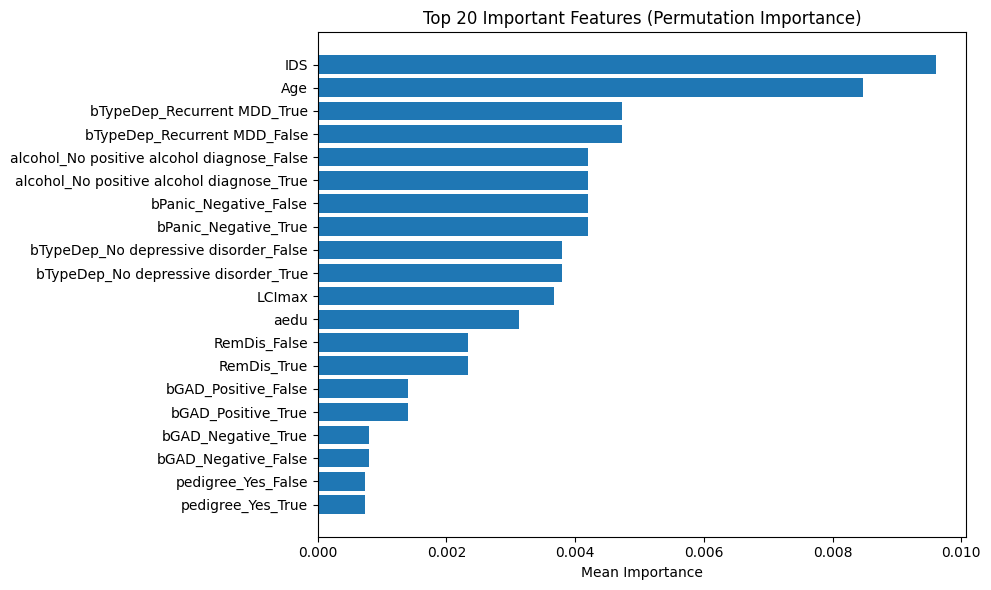

In [32]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

preprocessor = best_model5.named_steps['preprocessor']
svm_model = best_model5.named_steps['svm']

X_test_transformed = preprocessor.transform(X_test)

ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categoric_features)
scaled_feature_names = preprocessor.named_transformers_['num'].get_feature_names_out(numeric_features)
all_feature_names = list(scaled_feature_names) + list(ohe_feature_names)

result = permutation_importance(
    svm_model,
    X_test_transformed,
    Y_test,
    n_repeats=30,
    random_state=student_number,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance Mean': result.importances_mean,
    'Importance STD': result.importances_std
})

feature_importance_sorted = feature_importance.sort_values(by='Importance Mean', ascending=False)

print(feature_importance_sorted.head(20))

plt.figure(figsize=(10, 6))
plt.barh(feature_importance_sorted['Feature'][:20][::-1],
         feature_importance_sorted['Importance Mean'][:20][::-1])
plt.xlabel('Mean Importance')
plt.title('Top 20 Important Features (Permutation Importance)')
plt.tight_layout()
plt.show()



Bottom 20 features (Negative Importance):
                                              Feature  Importance Mean  \
4                                                  FQ        -0.004667   
39                            bSocPhob_Negative_False        -0.003733   
40                             bSocPhob_Negative_True        -0.003733   
41                            bSocPhob_Positive_False        -0.002800   
42                             bSocPhob_Positive_True        -0.002800   
3                                                 BAI        -0.002667   
12                                    PsychTreat_True        -0.002067   
11                                   PsychTreat_False        -0.002067   
18                   disType_depressive disorder_True        -0.002000   
17                  disType_depressive disorder_False        -0.002000   
14                      disType_anxiety disorder_True        -0.001533   
13                     disType_anxiety disorder_False        -0.00153

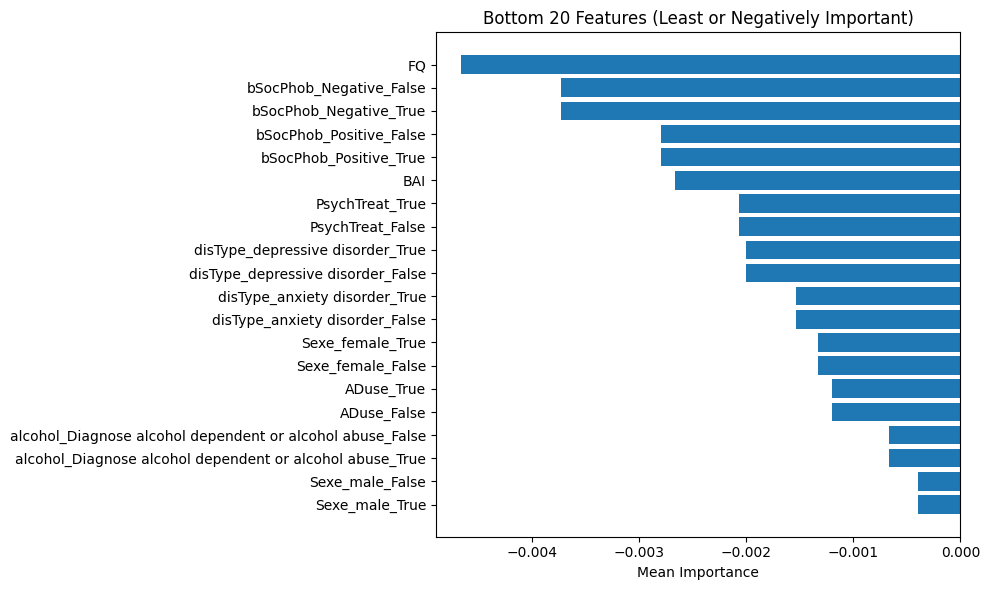

In [34]:
feature_importance_sorted_negative = feature_importance.sort_values(by='Importance Mean', ascending=True)

print("\nBottom 20 features (Negative Importance):")
print(feature_importance_sorted_negative.head(20))

plt.figure(figsize=(10, 6))
plt.barh(feature_importance_sorted_negative['Feature'][:20][::-1],
         feature_importance_sorted_negative['Importance Mean'][:20][::-1])
plt.xlabel('Mean Importance')
plt.title('Bottom 20 Features (Least or Negatively Important)')
plt.tight_layout()
plt.show()

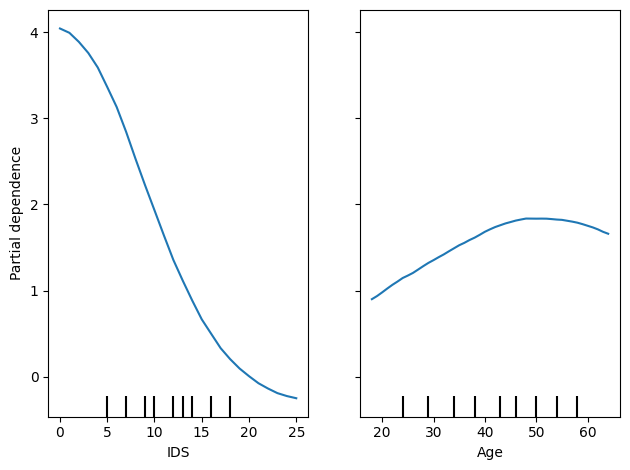

In [38]:
from sklearn.inspection import PartialDependenceDisplay

features_to_plot = ['IDS', 'Age']
PartialDependenceDisplay.from_estimator(
    best_model5,
    X,
    features=features_to_plot,
    target=2,
    kind="average",
    n_jobs=-1,
    grid_resolution=100
)

plt.tight_layout()
plt.show()


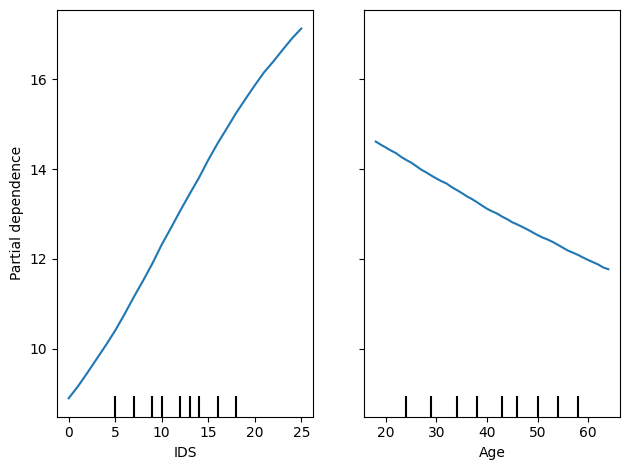

In [53]:
from sklearn.inspection import PartialDependenceDisplay

features_to_plot = ['IDS', 'Age']
PartialDependenceDisplay.from_estimator(
    best_model5,
    X,
    features=features_to_plot,
    target=20,
    kind="average",
    n_jobs=-1,
    grid_resolution=100
)

plt.tight_layout()
plt.show()


In [40]:
print(X.columns)


Index(['Age', 'aedu', 'IDS', 'BAI', 'FQ', 'LCImax', 'AO', 'RemDis', 'ADuse',
       'PsychTreat', 'disType_anxiety disorder', 'disType_comorbid disorder',
       'disType_depressive disorder', 'Sexe_female', 'Sexe_male',
       'pedigree_No', 'pedigree_Yes',
       'alcohol_Diagnose alcohol dependent or alcohol abuse',
       'alcohol_No positive alcohol diagnose', 'bTypeDep_Dysthymia',
       'bTypeDep_First onset MDD', 'bTypeDep_No depressive disorder',
       'bTypeDep_Recurrent MDD', 'bSocPhob_Negative', 'bSocPhob_Positive',
       'bGAD_Negative', 'bGAD_Positive', 'bPanic_Negative', 'bPanic_Positive',
       'bAgo_Negative', 'bAgo_Positive', 'sample_General population',
       'sample_Primary care', 'sample_Specialised mental health care'],
      dtype='object')


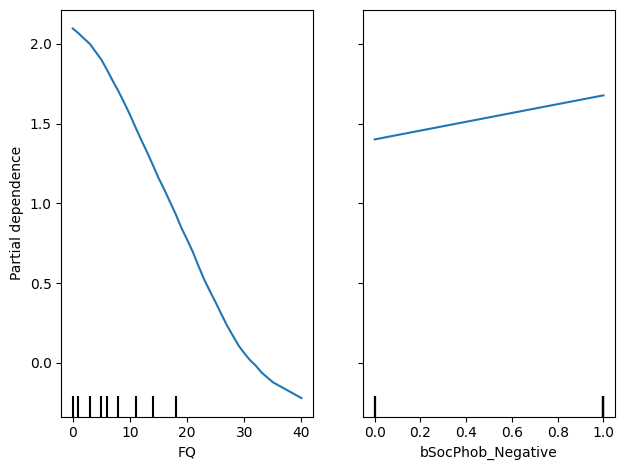

In [41]:
from sklearn.inspection import PartialDependenceDisplay

features_to_plot = ['FQ', 'bSocPhob_Negative']
PartialDependenceDisplay.from_estimator(
    best_model5,
    X,
    features=features_to_plot,
    target=2,
    kind="average",
    n_jobs=-1,
    grid_resolution=100
)

plt.tight_layout()
plt.show()


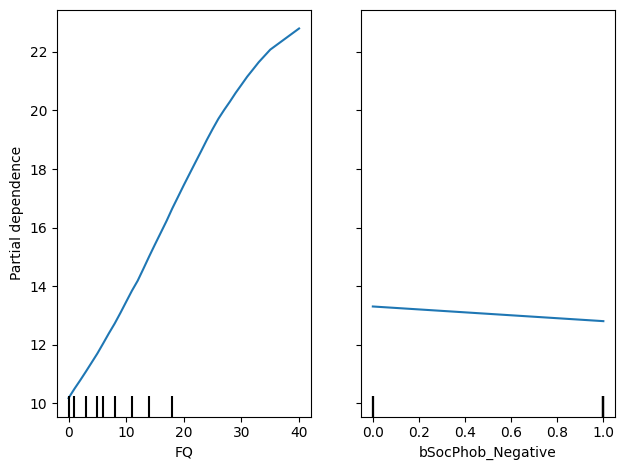

In [52]:
from sklearn.inspection import PartialDependenceDisplay

features_to_plot = ['FQ', 'bSocPhob_Negative']
PartialDependenceDisplay.from_estimator(
    best_model5,
    X,
    features=features_to_plot,
    target=20,
    kind="average",
    n_jobs=-1,
    grid_resolution=100
)

plt.tight_layout()
plt.show()


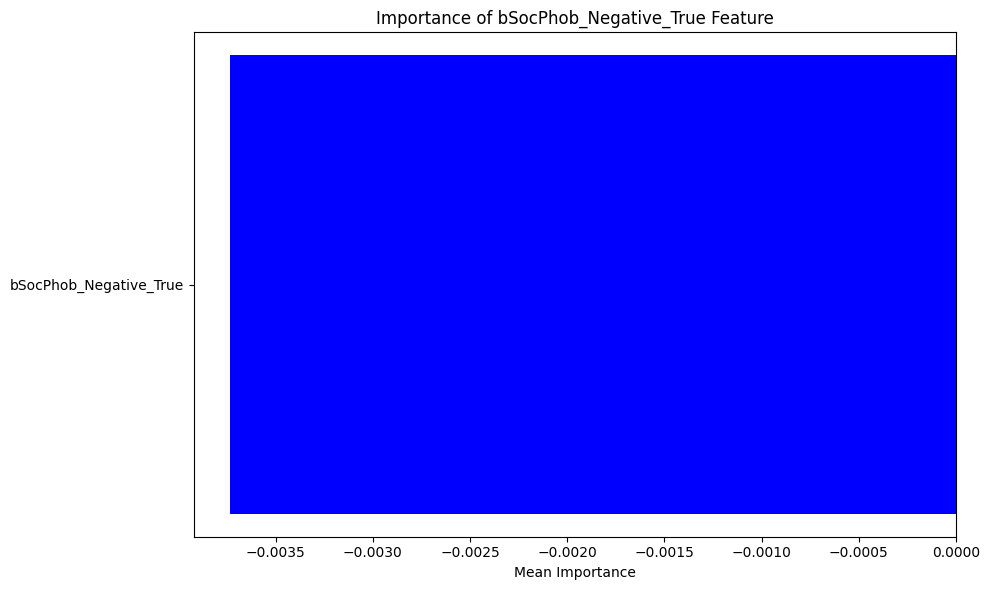

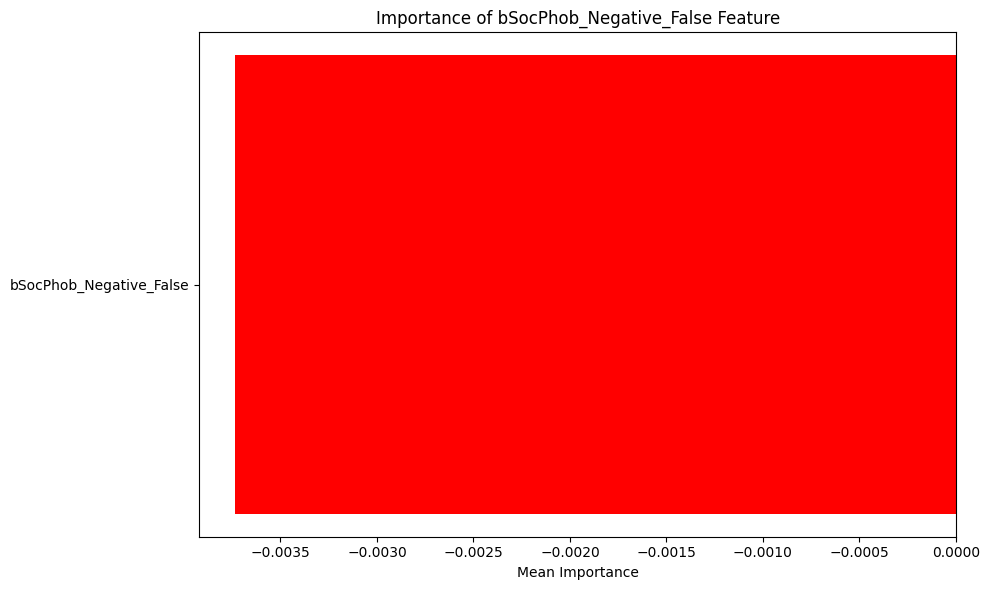

In [44]:
negative_true = feature_importance[feature_importance['Feature'] == 'bSocPhob_Negative_True']
negative_false = feature_importance[feature_importance['Feature'] == 'bSocPhob_Negative_False']

plt.figure(figsize=(10, 6))
plt.barh(negative_true['Feature'], negative_true['Importance Mean'], color='blue')
plt.xlabel('Mean Importance')
plt.title('Importance of bSocPhob_Negative_True Feature')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.barh(negative_false['Feature'], negative_false['Importance Mean'], color='red')
plt.xlabel('Mean Importance')
plt.title('Importance of bSocPhob_Negative_False Feature')
plt.tight_layout()
plt.show()

#predicting test set

In [45]:
from sklearn.metrics import classification_report, accuracy_score

y_pred = best_model5.predict(X_test)

print("Classification Report:\n", classification_report(Y_test, y_pred))

accuracy = accuracy_score(Y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.00      0.00      0.00         2
           2       0.00      0.00      0.00         1
           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00         5
           5       0.00      0.00      0.00        10
           6       0.00      0.00      0.00        15
           7       0.00      0.00      0.00        16
           8       0.21      0.31      0.25        13
           9       0.03      0.03      0.03        29
          10       0.00      0.00      0.00        35
          11       0.10      0.06      0.07        35
          12       0.15      0.13      0.14        45
          13       0.08      0.13      0.10        39
          14       0.03      0.03      0.03        40
          15       0.10      0.21      0.13        39
          16       0.10      0.09      0.09        34
   

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


David's Diagnosis

In [66]:
import pandas as pd

pat_dat = pd.read_csv("Patient.csv")
print(pat_dat.info())
print(pat_dat.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 20 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   disType     1 non-null      object 
 1   Sexe        1 non-null      object 
 2   Age         1 non-null      int64  
 3   aedu        1 non-null      int64  
 4   IDS         1 non-null      int64  
 5   BAI         1 non-null      int64  
 6   FQ          1 non-null      int64  
 7   LCImax      1 non-null      float64
 8   pedigree    1 non-null      object 
 9   alcohol     1 non-null      object 
 10  bTypeDep    1 non-null      object 
 11  bSocPhob    1 non-null      object 
 12  bGAD        1 non-null      object 
 13  bPanic      1 non-null      object 
 14  bAgo        1 non-null      object 
 15  AO          1 non-null      int64  
 16  RemDis      1 non-null      bool   
 17  sample      1 non-null      object 
 18  ADuse       1 non-null      bool   
 19  PsychTreat  1 non-null      bool 

In [70]:
print(df_MHpredict.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 21 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   disType     1500 non-null   object 
 1   Sexe        1500 non-null   object 
 2   Age         1500 non-null   int64  
 3   aedu        1500 non-null   int64  
 4   IDS         1500 non-null   int64  
 5   BAI         1500 non-null   int64  
 6   FQ          1500 non-null   int64  
 7   LCImax      1500 non-null   float64
 8   pedigree    1500 non-null   object 
 9   alcohol     1500 non-null   object 
 10  bTypeDep    1500 non-null   object 
 11  bSocPhob    1500 non-null   object 
 12  bGAD        1500 non-null   object 
 13  bPanic      1500 non-null   object 
 14  bAgo        1500 non-null   object 
 15  AO          1500 non-null   int64  
 16  RemDis      1500 non-null   bool   
 17  sample      1500 non-null   object 
 18  ADuse       1500 non-null   bool   
 19  PsychTreat  1500 non-null  

In [71]:
from sklearn.linear_model import LinearRegression

X = df_MHpredict.drop(columns=['dep_sev_fu'])
y = df_MHpredict['dep_sev_fu']

X = pd.get_dummies(X, drop_first=True)
pat_dat = pat_dat.drop(columns=['dep_sev_fu'], errors='ignore')
pat_dat = pd.get_dummies(pat_dat, drop_first=True)
pat_dat = pat_dat.reindex(columns=X.columns, fill_value=0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pat_data_scaled = scaler.transform(pat_dat)
model = LinearRegression()
model.fit(X_scaled, y)

predicted_severity = model.predict(pat_data_scaled)[0]
print(f"Predicted severity for David: {predicted_severity}")

if predicted_severity >= 17:
    print("David should be going to the intensive treatment program.")
else:
    print("David should not be going to the intensive treatment program.")


Predicted severity for David: 17.820790996381206
David should be going to the intensive treatment program.
